# Лекція 5. Локальний деплоймент і оптимізація моделей

Демо до лекції. Усі моделі в цьому ноутбуці запускаються **локально** через [Ollama](https://ollama.com), їх використання відбувається через HTTP-запити.

## 0. Налаштування середовища

### 0.0. Імпортуємо бібліотеки

In [3]:
import json
import subprocess
import sys
import time
import urllib.request

OLLAMA_URL = "http://localhost:11434"

### 0.1. Встановлюємо й запускаємо Ollama

Локально цю клітинку можна просто виконати: вона нічого не зробить.

In [4]:
IN_COLAB = "google.colab" in sys.modules
print("Running in Colab:", IN_COLAB)

if IN_COLAB:
    !sudo apt-get -qq install -y zstd > /dev/null
    !curl -fsSL https://ollama.com/install.sh | sh
    subprocess.Popen(["ollama", "serve"], stdout=subprocess.DEVNULL, stderr=subprocess.DEVNULL)
    time.sleep(5)

Running in Colab: True
debconf: unable to initialize frontend: Dialog
debconf: (No usable dialog-like program is installed, so the dialog based frontend cannot be used. at /usr/share/perl5/Debconf/FrontEnd/Dialog.pm line 79, <STDIN> line 1.)
debconf: falling back to frontend: Readline
debconf: unable to initialize frontend: Readline
debconf: (This frontend requires a controlling tty.)
debconf: falling back to frontend: Teletype
dpkg-preconfigure: unable to re-open stdin: 
>>> Installing ollama to /usr/local
>>> Downloading ollama-linux-amd64.tar.zst
######################################################################## 100.0%
>>> Creating ollama user...
>>> Adding ollama user to video group...
>>> Adding current user to ollama group...
>>> Creating ollama systemd service...
>>> The Ollama API is now available at 127.0.0.1:11434.
>>> Install complete. Run "ollama" from the command line.


### 0.2. Перевіряємо, що Ollama працює

Ollama — це HTTP-сервер на порту 11434. Функція `ollama()` надсилає йому запит і повертає відповідь як словник Python; якщо сервер працює, побачимо його версію.

In [5]:
def ollama(path, body=None, timeout=900):
    """POST-запит до Ollama (або GET, якщо body=None); повертає розібраний JSON."""
    data = json.dumps(body).encode() if body is not None else None
    req = urllib.request.Request(OLLAMA_URL + path, data=data, headers={"Content-Type": "application/json"})
    with urllib.request.urlopen(req, timeout=timeout) as resp:
        return json.load(resp)


print("Ollama version:", ollama("/api/version")["version"])

Ollama version: 0.40.16


In [4]:
!nvidia-smi

Tue Nov 17 17:27:20 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   58C    P0             38W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

## 1. Base, Instruct і Thinking

Порівнюємо три поведінки однієї й тієї самої моделі Qwen3 1.7B:
- **Base-модель** пройшла лише попереднє тренування: вона вміє передбачати наступний токен в інтернет-текстах, але не вміє відповідати на питання як асистент.
- **Instruct-модель** додатково донавчили на прикладах «інструкція → відповідь» у форматі діалогу.
- **Thinking** — режим, у якому Instruct-модель перед відповіддю генерує ланцюжок міркувань.

### 1.0. Завантажуємо моделі

Беремо одну й ту саму модель Qwen3 1.7B у двох версіях:
- **Base** — [Qwen3-1.7B-Base](https://huggingface.co/Qwen/Qwen3-1.7B-Base) у форматі GGUF (Q4_K_M) з Hugging Face;
- **Instruct** — офіційна [qwen3:1.7b](https://ollama.com/library/qwen3) з каталогу Ollama; вона ж уміє працювати в режимі міркування.

Перше завантаження займає кілька хвилин.

In [6]:
BASE_MODEL = "hf.co/mradermacher/Qwen3-1.7B-Base-GGUF:Q4_K_M"
INSTRUCT_MODEL = "qwen3:1.7b"

for m in (BASE_MODEL, INSTRUCT_MODEL):
    print("pull", m, "→", ollama("/api/pull", {"model": m, "stream": False})["status"])

pull hf.co/mradermacher/Qwen3-1.7B-Base-GGUF:Q4_K_M → success
pull qwen3:1.7b → success


### 1.1. Допоміжні функції

Нам вистачить двох ендпойнтів Ollama:
- `/api/generate` з `"raw": true` — передає моделі текст як є, **без chat template**;
- `/api/chat` — приймає список повідомлень і сам загортає їх у chat template моделі.

У Qwen3 режим міркування вмикається параметром `think`. З `think=True` модель спершу генерує ланцюжок міркувань (Ollama повертає його окремим полем `message.thinking`), а вже потім — відповідь. Функція `compare_thinking()` запускає запит в обох режимах і показує відповідь, кількість згенерованих токенів і час.

In [7]:
def generate_raw(model, prompt, max_tokens=120):
    """Продовження тексту без chat template — так «бачить» запит Base-модель."""
    r = ollama("/api/generate", {
        "model": model, "prompt": prompt, "raw": True, "stream": False,
        "options": {"temperature": 0, "seed": 1, "num_predict": max_tokens},
    })
    return r["response"]


def chat(model, prompt, think=False, max_tokens=3000):
    """Один запит у форматі діалогу; think=True вмикає режим міркування."""
    return ollama("/api/chat", {
        "model": model, "messages": [{"role": "user", "content": prompt}],
        "think": think, "stream": False,
        "options": {"temperature": 0, "seed": 1, "num_predict": max_tokens},
    })


def compare_thinking(prompt):
    for think in (False, True):
        r = chat(INSTRUCT_MODEL, prompt, think=think)
        msg = r["message"]
        print(f"=== think={think} | токенів: {r['eval_count']} | генерація: {r['eval_duration'] / 1e9:.1f} с")
        if msg.get("thinking"):
            print(f"--- міркування ({len(msg['thinking'])} символів), початок:")
            print(msg["thinking"][:600], "…")
        print("--- відповідь:")
        print(msg["content"])
        print()

### 1.2. Base: модель просто продовжує текст

Поставимо Base- та Instruct-моделі однакове питання.

In [8]:
QUESTION = "Яка столиця Франції?"

In [9]:
print(generate_raw(BASE_MODEL, QUESTION))

 Як називається найбільша річка Франції? Як називається найбільша річка Франції, яка розташована в Північній Америці? Як називається найбільша річка Франції, яка розташована в Півдні Франції? Як називається найбільша р


In [10]:
prompt = """
What is the capital of Germany?
answer - Berlin

What is the capital of Italy?
answer - Rome

What is the capital of Spain?
answer - Madrid

What is the capital of France?
"""

print(generate_raw(BASE_MODEL, prompt, max_tokens=15))

answer - Paris

What is the capital of Japan?
answer - Tokyo




Для Base-моделі «Яка столиця Франції?» схоже на початок списку питань вікторини — тож вона продовжує цей список, а не відповідає.

### 1.3. Instruct: модель відповідає на питання

In [11]:
print(chat(INSTRUCT_MODEL, QUESTION)["message"]["content"])

Столиця Франції — це **Париж**.


### 1.4. Instruct проти Thinking: багатокрокова задача

In [12]:
compare_thinking(
    "У кошику 3 яблука. Марія поклала туди ще 2 пакети по 4 яблука, "
    "а потім зʼїла 2 яблука. Скільки яблук у кошику?"
)

=== think=False | токенів: 252 | генерація: 2.0 с
--- відповідь:
Розглянемо ситуацію крок за кроком:

1. **У кошику 3 яблука.**  
2. **Марія поклала туди ще 2 пакети по 4 яблука.**  
   - Кожен пакет містить 4 яблука, тому:
     $$
     2 \text{ пакети} \times 4 \text{ яблука} = 8 \text{ яблука}
     $$
   - Значить, після додавання пакетів у кошик буде:
     $$
     3 + 8 = 11 \text{ яблука}
     $$
3. **Марія зʼїла 2 яблука.**  
   - Після з’ївання:
     $$
     11 - 2 = 9 \text{ яблука}
     $$

**Відповідь:**  
$$
\boxed{9}
$$

=== think=True | токенів: 569 | генерація: 4.7 с
--- міркування (1410 символів), початок:
Okay, let's see. So the problem is about Maria putting some apples in a basket and then eating some. Let me break it down step by step.

First, the basket starts with 3 apples. Then, Maria adds 2 packages, each containing 4 apples. So, I need to calculate how many apples she adds in total. Each package has 4 apples, and there are 2 packages. So that's 2 times 4, which i

Без міркувань модель згенерувала 252 токени за 2,1 с, а з Thinking — 569 токенів за 4,9 с. Міркування генеруються англійською через особливості навчання моделі, хоча остаточна відповідь надається українською.

Обидва режими відповідають правильно, але з міркуванням модель генерує в кілька разів більше токенів — а користувач бачить відповідь лише після них. Зверніть увагу: міркує модель англійською, хоча питання українською.

In [13]:
compare_thinking(
    "У тебе є 3 коробки. На першій написано 'Яблука', "
    "на другій 'Апельсини', на третій 'Яблука й апельсини'. "
    "Усі написи неправильні. "
    "Ти можеш витягнути лише один фрукт з однієї коробки. "
    "З якої коробки потрібно витягнути фрукт, "
    "щоб визначити вміст усіх трьох? Поясни відповідь."
)

=== think=False | токенів: 666 | генерація: 5.5 с
--- відповідь:
Розглянемо ситуацію:

- Перша коробка: **«Яблука»** — **неправильна**. Значить, в ній **не є яблук**, а може бути **апельсинами**, **яблука й апельсини**, або **іншим фруктом**.
- Друга коробка: **«Апельсини»** — **неправильна**. Значить, в ній **не є апельсинів**, а може бути **яблука**, **яблука й апельсини**, або **іншим фруктом**.
- Третя коробка: **«Яблука й апельсини»** — **неправильна**. Значить, в ній **не є яблука й апельсинів**, а може бути **яблука**, **апельсини**, або **іншим фруктом**.

---

### Визначення:

Ми маємо **три коробки**, кожна з яких має неправильну назву. Нам потрібно **витягнути лише один фрукт** з однієї коробки, щоб **визначити вміст усіх трьох**.

---

### Відповідь:

**Потрібно витягнути фрукт з третьої коробки.**

**Пояснення:**

- Якщо витягнемо **яблуко** з **третій коробки**, то:
  - Якщо в ній **яблуко**, то **яблука й апельсини** не є (ось бо вона неправильна).
  - Якщо в ній **апель

In [14]:
compare_thinking(
    "У класі 30 учнів. 18 вивчають англійську, "
    "15 вивчають німецьку, а 5 не вивчають жодної "
    "з цих мов. Скільки учнів вивчають обидві мови? "
    "Вкажи лише число."
)

=== think=False | токенів: 248 | генерація: 2.1 с
--- відповідь:
Для розв'язання задачі використаємо **закон висновку** (закон віднімання):

$$
\text{Кількість учнів, які вивчають обидві мови} = \text{Кількість учнів, які вивчають англійську} + \text{Кількість учнів, які вивчають німецьку} - \text{Кількість учнів, які вивчають хоча б одну мову}
$$

Звідси:

$$
\text{Кількість учнів, які вивчають обидві мови} = 18 + 15 - (30 - 5)
$$

$$
= 33 - 25 = 8
$$

**Відповідь: 8**

=== think=True | токенів: 782 | генерація: 6.8 с
--- міркування (2761 символів), початок:
Okay, let's see. There's a class with 30 students. Alright, so 18 are studying English, 15 are studying German, and 5 aren't studying either. The question is asking how many students are studying both English and German. Hmm, okay.

First, I remember that when dealing with overlapping groups, it's useful to use the principle of inclusion-exclusion. Let me recall that formula. It says that the number of elements in the union of two

In [15]:
compare_thinking(
    "Є три людини: Анна, Богдан і Віктор. "
    "Один завжди говорить правду, один завжди бреше, "
    "а третій може говорити як правду, так і неправду. "
    "Анна каже: 'Богдан завжди бреше'. "
    "Богдан каже: 'Віктор завжди говорить правду'. "
    "Віктор каже: 'Я не той, хто завжди говорить правду'. "
    "Визнач, хто з них завжди говорить правду, "
    "хто завжди бреше, а хто може говорити будь-що."
)

=== think=False | токенів: 1077 | генерація: 9.6 с
--- відповідь:
Давайте розглянемо умову:

- **Анна** — **відповідає правду** (відповідає **так** або **ні**).
- **Богдан** — **бре** (відповідає **ні** або **так**).
- **Віктор** — **може говорити як правду, так і неправду**.

Умови:

1. **Анна** каже: **"Богдан завжди бреше"**.
2. **Богдан** каже: **"Віктор завжди говорить правду"**.
3. **Віктор** каже: **"Я не той, хто завжди говорить правду"**.

---

### Підставимо умови у формі логічних висловлень:

1. **Анна**:
   - Якщо Анна говорить правду, то **Богдан завжди бреше**.
   - Якщо Анна бре, то **Богдан не завжди бреше**.

2. **Богдан**:
   - Якщо Богдан говорить правду, то **Віктор завжди говорить правду**.
   - Якщо Богдан бре, то **Віктор не завжди говорить правду**.

3. **Віктор**:
   - Якщо Віктор говорить правду, то **Віктор не завжди говорить правду** (це суперечить, бо він говорить правду).
   - Якщо Віктор бре, то **Віктор завжди говорить правду**.

---

### Розглянемо варі

Для перевірки використано логічну задачу про Анну, Богдана та Віктора, які мають різні ролі щодо правдивості висловлювань. Без Thinking модель дала неправильну відповідь, а з Thinking правильно визначила: Анна говорить правду, Богдан бреше, Віктор може говорити будь-що.

### 1.5. Міркування не гарантують правильності

In [16]:
compare_thinking("Скільки разів літера «р» трапляється в слові «трансформер»?")

=== think=False | токенів: 227 | генерація: 2.0 с
--- відповідь:
Щоб визначити, скільки разів літера **«р»** трапляється в слові **«трансформер»**, зробимо так:

Слово: **трансформер**

Розбілем його на складні слова:

- **транс**  
- **формер**

Тепер зіштовхуємо літеру **«р»** в кожному з складних слів:

1. **транс** — не має літери «р»  
2. **формер** — має **1** відтінок «р» (відтінок «р» у слові **формер**)

Отже, літера **«р»** трапляється **1 раз** в слові **«трансформер»**.

**Відповідь: 1 раз.**

=== think=True | токенів: 659 | генерація: 5.8 с
--- міркування (1490 символів), початок:
Okay, let's see. The user is asking how many times the letter "р" appears in the word "трансформер". First, I need to make sure I know the correct spelling of the word. The word in question is "трансформер". Let me write it out: трансформер.

Now, I need to check each letter one by one. Let's start from the beginning. The first letter is "т" which is "t" in Ukrainian, but the question is about th

Модель помиляється, оскільки обробляє текст токенами, а не окремими літерами, тому не завжди точно виконує символьний підрахунок; режим Thinking цього не гарантує. Перевірка кодом `print("трансформер".count("р"))` повертає 3, тоді як обидва режими моделі відповіли 2.

In [17]:
word = "трансформер"

print("Кількість літер р:", word.count("р"))

for i, letter in enumerate(word, start=1):
    print(i, letter)

Кількість літер р: 3
1 т
2 р
3 а
4 н
5 с
6 ф
7 о
8 р
9 м
10 е
11 р


Правильна відповідь — 3 (т**р**ансфо**р**ме**р**), але мала модель помиляється в обох режимах. Чому так — подумайте самі (це питання до лабораторної роботи).

Спробуйте власні запити: де режим міркування справді допомагає, а де лише витрачає токени?

## 2. Квантизація з Quanto

Завантажимо ту саму модель у чотирьох варіантах — від оригінальних 16 біт до 2 біт — і подивимося, що квантизація змінює в памʼяті, швидкості та якості. Якість перевіримо трьома способами: перплексією, перекладом з автоматичними метриками й очима — на вільній генерації тексту.

**Quanto.** [Optimum Quanto](https://github.com/huggingface/optimum-quanto) — бібліотека квантизації від Hugging Face, один із бекендів [Optimum](https://huggingface.co/docs/optimum). У Transformers вона підключається через [`QuantoConfig`](https://huggingface.co/docs/transformers/quantization/quanto) і квантизує модель прямо під час завантаження, тому окремий файл з квантизованими вагами не потрібен. Квантизуються ваги лінійних шарів (`nn.Linear`) — у них більшість параметрів моделі, а ембединги, нормалізації та вихідний шар лишаються в 16 бітах.

| Варіант | Біт на вагу | Що це |
|---|---|---|
| fp16 | 16 | Оригінальні ваги, точка відліку |
| int8 | 8 | 8-бітні цілі числа з масштабом |
| int4 | 4 | 4-бітні цілі числа, ваги діляться на блоки з власними масштабами |
| int2 | 2 | 2-бітні цілі числа — лише 4 можливі значення на вагу; тут модель має зламатися |

**Обчислення.** Множити числа в цих форматах напряму T4 не вміє, тому перед множенням ваги розпаковуються в 16 біт. Тому памʼяті потрібно менше, а от генерація часто **не прискорюється**, а то й сповільнюється.

**Де запускати.** Секцію запускаємо **в Google Colab на GPU T4** (Runtime → Change runtime type → T4 GPU). Беремо формат **fp16**, а не bf16: T4 не підтримує bf16 апаратно, а для запуску готової моделі різниця між ними практично непомітна.

### 2.0. Встановлюємо бібліотеки й перевіряємо GPU

In [18]:
%pip uninstall -y -q diffusers  # optimum-quanto імпортує diffusers, якщо він є; передвстановлена в Colab версія несумісна з його torchao
%pip install -q "transformers==5.20.1" "accelerate==1.15.0" "optimum-quanto==0.2.7" "evaluate==0.4.6" "sacrebleu==2.6.0"

In [19]:
import gc
import time
from types import SimpleNamespace

import evaluate
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from IPython.display import Markdown, display
from optimum.quanto.library.extensions import get_extension
from transformers import AutoModelForCausalLM, AutoTokenizer, QuantoConfig

assert torch.cuda.is_available(), "Увімкніть GPU: Runtime → Change runtime type → T4 GPU"
DEVICE = "cuda"
DTYPE = torch.float16
print("GPU:", torch.cuda.get_device_name())


def unpack_weights(packed, bits):
    """Розпаковує 4- чи 2-бітні значення, по кілька упакованих в одному байті."""
    values_per_byte = 8 // bits
    mask = 2**bits - 1
    return torch.cat([(packed >> (bits * i)) & mask for i in range(values_per_byte)]).to(torch.uint8)


# Quanto на GPU компілює власні CUDA-ядра, розраховані на A100 і новіші; на T4 ця компіляція падає.
# На T4 з усіх цих ядер потрібна лише розпаковка int4/int2-ваг, тож підставляємо її версію на чистому PyTorch.
if torch.cuda.get_device_capability()[0] < 8:
    get_extension("quanto_cuda")._lib = SimpleNamespace(unpack=unpack_weights)

GPU: Tesla T4


### 2.1. Модель і варіанти квантизації

Беремо [Qwen3-4B-Instruct-2507](https://huggingface.co/Qwen/Qwen3-4B-Instruct-2507) — сильнішу модель того ж сімейства, що й у секції 1: 4B параметрів, лише Instruct-режим без міркувань. У fp16 вона займає ~8 GB і вміщається в T4 з його 16 GB.

In [20]:
MODEL_ID = "Qwen/Qwen3-4B-Instruct-2507"
tokenizer = AutoTokenizer.from_pretrained(MODEL_ID)

VARIANTS = {
    "fp16": None,
    "int8": QuantoConfig(weights="int8"),
    "int4": QuantoConfig(weights="int4"),
    "int2": QuantoConfig(weights="int2"),
}

config.json:   0%|          | 0.00/727 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/9.38k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json: reconstructing file:   0%|          |  0.00B / 11.4MB            

tokenizer.json: downloading bytes:           |  0.00B            

### 2.2. Що міряємо

**Перплексія** — стандартна автоматична метрика якості квантизації (нею міряє, зокрема, llama.cpp). Модель читає фіксований текст, і для кожного токена ми дивимося, яку ймовірність вона йому давала. Перплексія — це, грубо кажучи, з якої кількості варіантів модель у середньому «вагалася»: чим вона менша, тим краще модель знає мову й тему. Еталонних відповідей тут не потрібно, а число змінюється плавно, тому видно навіть невеликі втрати. Порівнювати перплексію можна лише в межах однієї мови: англійська й українська токенізуються по-різному.

**Переклад EN → UK** — реалістичне завдання з генерацією тексту, для якого є еталонні переклади. Порівнюємо переклад моделі з еталоном двома стандартними метриками з бібліотеки [Evaluate](https://huggingface.co/docs/evaluate):
- [**chrF**](https://github.com/huggingface/evaluate/blob/main/metrics/chrf/README.md) — наскільки збігаються послідовності символів (0–100);
- [**BLEU**](https://github.com/huggingface/evaluate/tree/main/metrics/sacrebleu) — наскільки збігаються послідовності слів (0–100). Сувора метрика: синонім чи інший порядок слів уже знижують бал.

**Вільна генерація** — лист, пояснення, план, код. Тут еталону немає, тож оцінюємо очима в 2.5.

Крім якості, для кожного варіанта записуємо **памʼять моделі** на GPU, **пік VRAM** і **швидкість генерації** (tokens/s).

In [21]:
PPL_TEXT = {
    "English": (
        "Photosynthesis is the process by which green plants, algae and some bacteria turn light energy into "
        "chemical energy. It takes place mainly in the leaves, inside small structures called chloroplasts, which "
        "contain the green pigment chlorophyll. Chlorophyll absorbs sunlight, and the plant uses this energy to "
        "combine carbon dioxide from the air with water from the soil. The result is glucose, a sugar that the "
        "plant uses for growth and as a store of energy, and oxygen, which is released into the atmosphere. "
        "Almost all life on Earth depends on photosynthesis: it produces the oxygen we breathe and forms the "
        "basis of most food chains."
    ),
    "Українська": (
        "Фотосинтез — це процес, під час якого зелені рослини, водорості та деякі бактерії перетворюють енергію "
        "світла на хімічну енергію. Він відбувається переважно в листках, усередині маленьких структур, які "
        "називають хлоропластами і які містять зелений пігмент хлорофіл. Хлорофіл поглинає сонячне світло, і "
        "рослина використовує цю енергію, щоб поєднати вуглекислий газ із повітря з водою із ґрунту. У результаті "
        "утворюються глюкоза — цукор, який рослина використовує для росту і як запас енергії, — та кисень, що "
        "виділяється в атмосферу. Майже все життя на Землі залежить від фотосинтезу: він дає кисень, яким ми "
        "дихаємо, і лежить в основі більшості харчових ланцюгів."
    ),
}

TRANSLATION = [
    # (речення англійською, еталонний переклад)
    ("The meeting has been moved to Thursday at three o'clock.", "Зустріч перенесли на четвер на третю годину."),
    ("Please send me the report by the end of the day.", "Будь ласка, надішліть мені звіт до кінця дня."),
    ("The library is closed on Sundays and public holidays.", "Бібліотека не працює в неділю та у святкові дні."),
    ("Our team fixed the bug, but the tests are still failing.", "Наша команда виправила помилку, але тести все ще не проходять."),
    ("It is going to rain tomorrow, so take an umbrella.", "Завтра буде дощ, тож візьміть парасольку."),
    ("The new model is smaller, but it answers almost as well as the old one.", "Нова модель менша, але відповідає майже так само добре, як стара."),
    ("I would like to book a table for two for seven o'clock tonight.", "Я хотів би забронювати столик на двох на сьому вечора."),
    ("The price includes breakfast and free Wi-Fi.", "У вартість входять сніданок і безкоштовний Wi-Fi."),
    ("Students must submit their lab work before the deadline.", "Студенти мають здати лабораторну роботу до кінцевого терміну."),
    ("If the server does not respond, restart it and check the logs.", "Якщо сервер не відповідає, перезапустіть його й перевірте логи."),
]
TRANSLATE_PROMPT = "Translate the following sentence into Ukrainian. Output only the translation.\n\n{}"

GEN_PROMPTS = [
    "Напиши короткий лист викладачеві з проханням перенести здачу лабораторної роботи на тиждень через хворобу.",
    "Поясни студентові першого курсу в 3–4 реченнях, що таке квантизація нейромережі.",
    "Explain in three sentences why the sky is blue.",
    "Склади план підготовки до іспиту з програмування на 5 днів, по одному пункту на день.",
    "Write a Python function that checks whether a string is a palindrome.",
]

### 2.3. Проганяємо всі варіанти

Дві допоміжні функції — перплексія тексту й генерація відповіді — і цикл по варіантах: завантажуємо модель, міряємо все потрібне, звільняємо памʼять. Займає кілька хвилин на варіант.

In [22]:
def perplexity(model, text):
    """exp(середня похибка передбачення наступного токена) на фіксованому тексті."""
    ids = tokenizer(text, return_tensors="pt").input_ids.to(DEVICE)
    with torch.no_grad():
        loss = model(ids, labels=ids).loss
    return float(torch.exp(loss))


def generate(model, prompt, max_new_tokens):
    """Відповідь без випадковості; повертає текст, кількість нових токенів і час генерації."""
    text = tokenizer.apply_chat_template([{"role": "user", "content": prompt}], tokenize=False, add_generation_prompt=True)
    inputs = tokenizer(text, return_tensors="pt").to(DEVICE)
    torch.cuda.synchronize()
    start = time.perf_counter()
    with torch.no_grad():
        output = model.generate(**inputs, max_new_tokens=max_new_tokens, do_sample=False)
    torch.cuda.synchronize()
    new_tokens = output[0, inputs.input_ids.shape[1]:]
    return tokenizer.decode(new_tokens, skip_special_tokens=True).strip(), len(new_tokens), time.perf_counter() - start


records = {}
for name, config in VARIANTS.items():
    gc.collect()
    torch.cuda.empty_cache()
    torch.cuda.reset_peak_memory_stats()
    model = AutoModelForCausalLM.from_pretrained(MODEL_ID, dtype=DTYPE, device_map=DEVICE, quantization_config=config)

    r = {"памʼять моделі, GB": torch.cuda.memory_allocated() / 1e9}
    for lang, text in PPL_TEXT.items():
        r[f"перплексія, {lang}"] = perplexity(model, text)
    r["переклади"] = [generate(model, TRANSLATE_PROMPT.format(src), 80)[0] for src, _ in TRANSLATION]
    generations = [generate(model, prompt, 200) for prompt in GEN_PROMPTS]
    r["генерації"] = [text for text, _, _ in generations]
    r["tokens/s"] = sum(n for _, n, _ in generations) / sum(s for _, _, s in generations)
    r["пік VRAM, GB"] = torch.cuda.max_memory_allocated() / 1e9
    records[name] = r
    print(f"{name}: готово")

    del model

model.safetensors.index.json:   0%|          | 0.00/32.8k [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 3 files:   0%|          | 0/3 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/238 [00:00<?, ?B/s]

fp16: готово


... (2 outputs left out)

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

int4: готово


Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

int2: готово


### 2.4. Памʼять, швидкість і автоматичні метрики

In [24]:
chrf = evaluate.load("chrf")
bleu = evaluate.load("sacrebleu")
references = [[ref] for _, ref in TRANSLATION]

summary = pd.DataFrame({
    name: {
        "памʼять моделі, GB": r["памʼять моделі, GB"],
        "пік VRAM, GB": r["пік VRAM, GB"],
        "tokens/s": r["tokens/s"],
        **{f"перплексія, {lang}": r[f"перплексія, {lang}"] for lang in PPL_TEXT},
        "chrF перекладу": chrf.compute(predictions=r["переклади"], references=references)["score"],
        "BLEU перекладу": bleu.compute(predictions=r["переклади"], references=references)["score"],
    }
    for name, r in records.items()
}).T.round(2)
summary

,"памʼять моделі, GB","пік VRAM, GB",tokens/s,"перплексія, English","перплексія, Українська",chrF перекладу,BLEU перекладу
fp16,8.04,8.64,17.33,2.67,2.40,55.22,23.71
int8,4.42,5.01,6.16,2.67,2.40,58.25,26.17
int4,2.73,3.32,2.93,2.81,2.76,55.34,29.79
int2,1.81,2.39,3.06,60091.86,34451480.00,0.19,0.12


Від fp16 до int4 перплексія збільшилася незначно, а якість перекладу загалом залишилася близькою. Найбільше погіршення відбулося між int4 та int2: перплексія різко зросла, а chrF і BLEU впали майже до нуля.

Ні, перплексія змінюється по-різному: на int4 англійська зросла з 2,67 до 2,81, а українська — з 2,40 до 2,76. Це узгоджується з висновком, що квантизація може неоднаково впливати на різні мови.

Відносно fp16 пам'ять зменшилася в 1,82 раза для int8, 2,95 раза для int4 і 4,44 раза для int2 через накладні витрати квантизації та неквантизовані компоненти. Генерація не прискорилася: швидкість знизилася з 16,67 до приблизно 3–7 токенів/с.

Пік VRAM більший, оскільки, крім ваг моделі, пам'ять займають KV-кеш, проміжні тензори та інші буфери обчислень. Наприклад, у fp16 пам'ять моделі становить 8,04 GB, а пік VRAM — 8,64 GB.

Модель Qwen3-4B має приблизно 4 млрд параметрів, тому у fp16 теоретично потребує близько 8 GB для ваг. Виміряна пам'ять моделі становить 8,04 GB, що близько до розрахунку.

Перплексія для кожної мови окремо. Вісь — логарифмічна: інакше на одному графіку не помістилися б і кілька одиниць, і сотні.

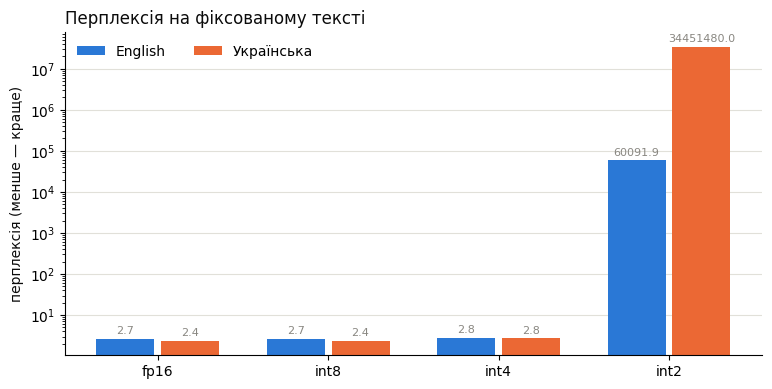

In [25]:
LANG_COLORS = {"English": "#2a78d6", "Українська": "#eb6834"}
INK, MUTED, GRID = "#0b0b0b", "#898781", "#e1e0d9"

variants = list(records)
x = np.arange(len(variants))
width = 0.38

fig, ax = plt.subplots(figsize=(9, 4.2))
for i, lang in enumerate(PPL_TEXT):
    values = summary[f"перплексія, {lang}"].values
    bars = ax.bar(x + (i - 0.5) * width, values, width - 0.04, color=LANG_COLORS[lang], label=lang)
    ax.bar_label(bars, labels=[f"{v:.1f}" for v in values], fontsize=8, color=MUTED, padding=2)
ax.set_yscale("log")
ax.set_xticks(x, variants)
ax.set_ylabel("перплексія (менше — краще)", color=INK)
ax.set_title("Перплексія на фіксованому тексті", loc="left", color=INK)
ax.legend(frameon=False, ncols=2, loc="upper left")
ax.grid(axis="y", color=GRID, linewidth=0.8)
ax.set_axisbelow(True)
for side in ("top", "right"):
    ax.spines[side].set_visible(False)
plt.show()

Переклади всіх варіантів поруч з еталоном:

In [26]:
translations = pd.DataFrame({"еталон": [ref for _, ref in TRANSLATION]}, index=[src for src, _ in TRANSLATION])
for name, r in records.items():
    translations[name] = r["переклади"]
translations

,еталон,fp16,int8,int4,int2
The meeting has been moved to Thursday at three o'clock.,Зустріч перенесли на четвер на третю годину.,"Зустріч була перенесена на четвер, о 15 годин.","Зустріч перенесли на четвер, о 15 годин.","Зустріч була перенесена на четвер, о 15 годин.",`` takenosthawkhhhawkoft0houghth``t`\'uleh'thh...
Please send me the report by the end of the day.,"Будь ласка, надішліть мені звіт до кінця дня.",Надішліть мені звіт до кінця дня.,Надішліть мені звіт до кінця дня.,Надішліть мені звіт до кінця дня.,takenawns between't```````````````````h``` \`e...
The library is closed on Sundays and public holidays.,Бібліотека не працює в неділю та у святкові дні.,Бібліотека закривається у неділі та дні відпоч...,Бібліотека закривається у неділі та дні відпоч...,Бібліотека відкрита тільки з 1 по 7.,`ever �house �take caught}}house0}0 taken take...
"Our team fixed the bug, but the tests are still failing.","Наша команда виправила помилку, але тести все ...","Наша команда виправила баг, але тестування все...","Наша команда виправила баг, але тестування все...","Наша команда виправила баг, але тести все ще н...",fil}'sand ever0'f}'h \n'}'}''}'' \n' \n \n ...
"It is going to rain tomorrow, so take an umbrella.","Завтра буде дощ, тож візьміть парасольку.","Завтра піде дощ, тому взміть засіб.","Завтра піде дощ, тому взміть з собою парасольку.","Завтра буде дощ, тому взміть засіб.",}again \蚊} taken \neverh. \n \nagain \n \n...
"The new model is smaller, but it answers almost as well as the old one.","Нова модель менша, але відповідає майже так са...","Новий модель менший, але відповідає почти так ...","Новий модель менший, але відповідає приблизно ...","Новий модель менший, але відповідає почти так ...",fil��''}\n0. between'h ’h ` between betweenfec...
I would like to book a table for two for seven o'clock tonight.,Я хотів би забронювати столик на двох на сьому...,Я бажаю забронювати стіл для двох на сім годин...,Я бажаю забронювати стіл для двох на сім годин...,Я б хотів зареєструвати стіл для двох на 7 год...,``ever``always```comeight`[\n`letic touched`ev...
The price includes breakfast and free Wi-Fi.,У вартість входять сніданок і безкоштовний Wi-Fi.,Ціна включає початок дня та безкоштовний Wi-Fi.,Ціна включає початок дня та безкоштовний Wi-Fi.,Ціна включає початок дня та вільний Wi-Fi.,.前所eterminefilosterone0 00 \00 \tt011011OFF00e...
Students must submit their lab work before the deadline.,Студенти мають здати лабораторну роботу до кін...,Студенти повинні подати свою лабораторну робот...,Студенти повинні подати свою лабораторну робот...,Студенти повинні відправляти лабораторну робот...,he $everearned a0001100evers \n0\n\nhehe0'tou...
"If the server does not respond, restart it and check the logs.","Якщо сервер не відповідає, перезапустіть його ...","Якщо сервер не відповідає, перезапустіть його ...","Якщо сервер не відповідає, перезапустіть його ...","Якщо сервер не відповідає, перезапустіть його ...",ever. taken againoughtbetweenhtonhhofthhbetwee...


Наприклад, fp16 переклала «Зустріч була перенесена на четвер, о 15 годин» замість еталонного «Зустріч перенесли на четвер на третю годину», зберігши основний зміст. BLEU знижує оцінку через відмінності у словах і словосполученнях, а chrF частково враховує схожість на рівні символів, хоча також штрафує за відмінності.

### 2.5. Сліпе порівняння: fp16 проти int4

Автоматичні метрики показали, наскільки int4 відрізняється від fp16 у числах. Тепер перевірмо очима — так, як це роблять оцінювачі-люди: для кожного запиту показуємо дві відповіді, fp16 та int4, **у випадковому порядку й без підписів**. Ваше завдання — обрати кращу.

In [27]:
rng = np.random.default_rng(0)
BLIND_ORDER = [rng.permutation(["fp16", "int4"]) for _ in GEN_PROMPTS]

for i, prompt in enumerate(GEN_PROMPTS):
    display(Markdown(f"---\n#### Запит {i + 1}: {prompt}"))
    for label, name in zip("AB", BLIND_ORDER[i]):
        display(Markdown(f"**Відповідь {label}:**\n\n{records[name]['генерації'][i]}"))

---
#### Запит 1: Напиши короткий лист викладачеві з проханням перенести здачу лабораторної роботи на тиждень через хворобу.

**Відповідь A:**

Ось приклад короткого і відповідного листа викладачеві:

---

**Лист викладачеві**

Увага, викладаче!

Прохання перенести здачу лабораторної роботи на наступний тиждень через хворобу. Здача відкладається на [указати дату, наприклад: 10 листопада 2024 року].

З повагою,  
[Ваше ім’я]  
[Номер групи]  
[Курс, наприклад: 3 курс, група 12]  

---

Якщо потрібно — можу допомогти адаптувати лист під конкретний предмет або стиль

**Відповідь B:**

Викладачу [Ім’я та прізвище],

Прохання про перенесення здачі лабораторної роботи на наступний тиждень через хворобу.

З повагою,  
[Ваше прізвище, ім’я, номер групи]

---
#### Запит 2: Поясни студентові першого курсу в 3–4 реченнях, що таке квантизація нейромережі.

**Відповідь A:**

Квантизація нейромережі — це процес зменшення точності ваг між нейронами в мережі, щоб зменшити об’єм пам’яті та швидкість обчислень. Вона полягає у заміні дробових чисел (наприклад, з плаваючою комою) на цілі числа (наприклад, з кількома бітами). Це дозволяє запускати мережі на пристроях з обмеженою відповідністю, таких як мобільні телефони або IoT-апарати. Насправді, квантизація не втрачає повно

**Відповідь B:**

Квантизація нейромережі — це процес зменшення точності ваг (зв'язків між нейронами) до тих рівнів, що можна зберігати в комп'ютері з меншою відповідністю до об’ємних ресурсів. Це робиться для зменшення об’єму пам’яті та швидкості обчислень. Наприклад, ваги можуть бути зображено як цілі числа (наприклад, 8 біт) замість дробових чисел. Це зручно для використання на пристроях з обмеженими ресурс

... (5 outputs left out)

**Відповідь B:**

Ось чіткий і практичний план підготовки до іспиту з програмування на 5 днів — по одному ключовому темі на день. Цей план призначений для студентів, які вивчають програмування на початковому або середньому рівні (наприклад, на мові Python, Java або C++), але може бути адаптований під будь-яку мову.

---

**День 1: Основні структури даних та їх використання**

- Повторити: змінні, типи даних, оператори, вирази.
- Вивчити: списки, кортежі, слов

---
#### Запит 5: Write a Python function that checks whether a string is a palindrome.

**Відповідь A:**

Sure! Here's a Python function that checks whether a string is a palindrome:

```python
def is_palindrome(s):
    """
    Check if a string is a palindrome (reads the same forwards and backwards).
    
    Args:
        s (str): The string to check.
    
    Returns:
        bool: True if the string is a palindrome, False otherwise.
    
    Note:
        This function is case-insensitive and ignores non-alphanumeric characters.
    """
    # Remove non-alphanumeric characters and convert to lowercase
    cleaned = ''.join(char.lower() for char in s if char.isalnum())
    
    # Check if the cleaned string reads the same forwards and backwards
    return cleaned == cleaned[::-1]
```

### Example usage:

```python
print(is_palindrome("racecar"))        # True
print(is_palindrome("A man a plan a canal Panama"))  # True
print(is_palindrome("hello"))         # False
print(is_palindrome

**Відповідь B:**

Sure! Here's a Python function that checks whether a given string is a palindrome:

```python
def is_palindrome(s):
    """
    Check whether a string is a palindrome (reads the same forwards and backwards).
    
    Args:
        s (str): The string to check.
    
    Returns:
        bool: True if the string is a palindrome, False otherwise.
    """
    # Remove non-alphanumeric characters and convert to lowercase
    cleaned = ''.join(char.lower() for char in s if char.isalnum())
    
    # Check if the cleaned string reads the same forwards and backwards
    return cleaned == cleaned[::-1]

# Example usage:
print(is_palindrome("A man, a plan, a canal: Panama"))  # True
print(is_palindrome("race a car"))                     # False
print(is_palindrome("racecar"))                       # True
```

### Explanation:
- The function removes all non-alphanumeric characters (like spaces, punctuation) and

In [28]:
for i, order in enumerate(BLIND_ORDER, 1):
    print(f"Запит {i}: A = {order[0]}, B = {order[1]}")

Запит 1: A = fp16, B = int4
Запит 2: A = fp16, B = int4
Запит 3: A = fp16, B = int4
Запит 4: A = int4, B = fp16
Запит 5: A = int4, B = fp16


У сліпому порівнянні fp16 перемогла двічі, int4 — один раз, ще двічі відповіді виявилися рівноцінними. Це загалом узгоджується з невеликою різницею автоматичних метрик, хоча в окремих відповідях помітні відмінності стилю та якості.

Було обрано fp16 двічі, int4 один раз і «однаково» двічі. П'яти порівнянь недостатньо для надійного висновку: бажано провести хоча б 50–100 оцінювань на різноманітних запитах.

Для кожного запиту запишіть **"A"** або **"B"** — яка відповідь краща, або **"="**, якщо однакові за якістю. Потім запустіть наступну клітинку, щоб дізнатися, де була яка модель.

In [29]:
VOTES = {1: "", 2: "", 3: "", 4: "", 5: ""}

In [30]:
VOTES = {
    1: "B",
    2: "A",
    3: "=",
    4: "B",
    5: "=",
}

In [31]:
if all(v in ("A", "B", "=") for v in VOTES.values()):
    rows = []
    for i, vote in VOTES.items():
        order = dict(zip("AB", BLIND_ORDER[i - 1]))
        rows.append({"запит": GEN_PROMPTS[i - 1], "A": order["A"], "B": order["B"],
                     "ваш вибір": "однаково" if vote == "=" else order[vote]})
    display(pd.DataFrame(rows))
    choices = [r["ваш вибір"] for r in rows]
    print(f"fp16 краща: {choices.count('fp16')}, int4 краща: {choices.count('int4')}, однаково: {choices.count('однаково')}")
else:
    print('Заповніть VOTES значеннями "A", "B" або "=" для всіх 5 запитів.')

,запит,A,B,ваш вибір
0,Напиши короткий лист викладачеві з проханням п...,fp16,int4,int4
1,Поясни студентові першого курсу в 3–4 реченнях...,fp16,int4,fp16
2,Explain in three sentences why the sky is blue.,fp16,int4,однаково
3,Склади план підготовки до іспиту з програмуван...,int4,fp16,fp16
4,Write a Python function that checks whether a ...,int4,fp16,однаково


fp16 краща: 2, int4 краща: 1, однаково: 2


### 2.6. Відповіді всіх варіантів

Тепер, коли сліпе порівняння зроблено, — відповіді всіх варіантів з підписами, включно з int8 та int2. Еталону тут немає, тож читаємо самі.

In [32]:
for i, prompt in enumerate(GEN_PROMPTS):
    display(Markdown(f"---\n#### Запит {i + 1}: {prompt}"))
    for name, r in records.items():
        display(Markdown(f"**{name}:**\n\n{r['генерації'][i]}"))

---
#### Запит 1: Напиши короткий лист викладачеві з проханням перенести здачу лабораторної роботи на тиждень через хворобу.

**fp16:**

Ось приклад короткого і відповідного листа викладачеві:

---

**Лист викладачеві**

Увага, викладаче!

Прохання перенести здачу лабораторної роботи на наступний тиждень через хворобу. Здача відкладається на [указати дату, наприклад: 10 листопада 2024 року].

З повагою,  
[Ваше ім’я]  
[Номер групи]  
[Курс, наприклад: 3 курс, група 12]  

---

Якщо потрібно — можу допомогти адаптувати лист під конкретний предмет або стиль

**int8:**

Ось приклад короткого листа викладачеві:

---

**Дорогий [Ім’я викладача]!**

Прохання перенести здачу лабораторної роботи на наступний тиждень через хворобу.  
Буду дуже вдячний за розуміння та гнучкість.

З повагою,  
[Ваше ім’я]  
[Номер групи]  
[Контактна інформація, якщо потрібно]

---

Цей лист короткий, виразний та відповідає формату прохання. Можна адаптувати під конкретну ситуацію.

**int4:**

Викладачу [Ім’я та прізвище],

Прохання про перенесення здачі лабораторної роботи на наступний тиждень через хворобу.

З повагою,  
[Ваше прізвище, ім’я, номер групи]

**int2:**

°°h\ter°\n h hsd°°ampton \ \
 \
:
h h h h : had had had had had had again had had had had h bettb h hhtonhtonsd**leehtonhtonsdhtonhtonhtonhtonhtonhtonhton (%) nuts9 system \ \ rest  \} \} \n \ \ \ \  \ \ \ \ h \ \ \ h \ \ h \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \  \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ the \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \

---
#### Запит 2: Поясни студентові першого курсу в 3–4 реченнях, що таке квантизація нейромережі.

... (15 outputs left out)

**fp16:**

Sure! Here's a Python function that checks whether a given string is a palindrome:

```python
def is_palindrome(s):
    """
    Check whether a string is a palindrome (reads the same forwards and backwards).
    
    Args:
        s (str): The string to check.
    
    Returns:
        bool: True if the string is a palindrome, False otherwise.
    """
    # Remove non-alphanumeric characters and convert to lowercase
    cleaned = ''.join(char.lower() for char in s if char.isalnum())
    
    # Check if the cleaned string reads the same forwards and backwards
    return cleaned == cleaned[::-1]

# Example usage:
print(is_palindrome("A man, a plan, a canal: Panama"))  # True
print(is_palindrome("race a car"))                     # False
print(is_palindrome("racecar"))                       # True
```

### Explanation:
- The function removes all non-alphanumeric characters (like spaces, punctuation) and

**int8:**

Sure! Here's a Python function that checks whether a given string is a palindrome:

```python
def is_palindrome(s):
    """
    Check whether a string is a palindrome (reads the same forwards and backwards).
    
    Args:
        s (str): The string to check.
    
    Returns:
        bool: True if the string is a palindrome, False otherwise.
    """
    # Remove non-alphanumeric characters and convert to lowercase
    cleaned = ''.join(char.lower() for char in s if char.isalnum())
    
    # Check if the cleaned string reads the same forwards and backwards
    return cleaned == cleaned[::-1]

# Example usage:
print(is_palindrome("A man, a plan, a canal: Panama"))  # True
print(is_palindrome("race a car"))                     # False
print(is_palindrome("racecar"))                       # True
```

### Explanation:
- The function removes all non-alphanumeric characters (like spaces, punctuation) and

**int4:**

Sure! Here's a Python function that checks whether a string is a palindrome:

```python
def is_palindrome(s):
    """
    Check if a string is a palindrome (reads the same forwards and backwards).
    
    Args:
        s (str): The string to check.
    
    Returns:
        bool: True if the string is a palindrome, False otherwise.
    
    Note:
        This function is case-insensitive and ignores non-alphanumeric characters.
    """
    # Remove non-alphanumeric characters and convert to lowercase
    cleaned = ''.join(char.lower() for char in s if char.isalnum())
    
    # Check if the cleaned string reads the same forwards and backwards
    return cleaned == cleaned[::-1]
```

### Example usage:

```python
print(is_palindrome("racecar"))        # True
print(is_palindrome("A man a plan a canal Panama"))  # True
print(is_palindrome("hello"))         # False
print(is_palindrome

**int2:**

\
 \'  
\' 
\' \ \ \ \ \\'\' \ \ \ \ \\' \\' \ OFF ** \ - [\'0 \'\'\'\'\'\' \' \ \ \ 
 
  \ 
5  \ \ \\ \ 
 
0 \ -  - - - - - - - - - - -  \ \ - - - - \  
\' \ \\'\' \\'\'    - - sent\'\'\'\'\n\'\' \ \ \ \ \ \ \ \ \ \ \ \ \ \ - - \ -  - -  -\'20\' \' - - - - - - - - - \ \' - -':
 - - - - - - - - - -   - - - - - - - - - - - - - - - - - - - - - -LOCK  \ -  \ -\' \ \ \   PRO \ - - - - - -

У int2 модель майже повністю втрачає здатність формувати осмислений текст: генерує випадкові символи, повторення слів і незрозумілі фрагменти. В int4 таких критичних проблем немає, хоча вже помітні граматичні помилки, неточності формулювань і незавершені відповіді.

In [33]:
import pickle

with open("results_4b.pkl", "wb") as f:
    pickle.dump(records, f)

print("Результати 4B збережено!")

Результати 4B збережено!


In [34]:
from google.colab import files

files.download("results_4b.pkl")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Процес виконувався понад 30 хвилин, тому я вирішив зберегти результат

In [33]:
import pickle
from google.colab import files

uploaded = files.upload()

with open("results_4b.pkl", "rb") as f:
    records_4b = pickle.load(f)

print("Результати відновлено!")
print("Моделі:", list(records_4b.keys()))

Результати відновлено!
Моделі: ['fp16', 'int8', 'int4', 'int2']


In [37]:
import pickle
import gc
import time

MODEL_ID = "Qwen/Qwen3-1.7B"
tokenizer = AutoTokenizer.from_pretrained(MODEL_ID)

records_17b = {}

for name, config in VARIANTS.items():
    gc.collect()
    torch.cuda.empty_cache()
    torch.cuda.reset_peak_memory_stats()

    print(f"\nТестування {name}...", flush=True)

    model = AutoModelForCausalLM.from_pretrained(
        MODEL_ID,
        dtype=DTYPE,
        device_map=DEVICE,
        quantization_config=config
    )

    r = {
        "памʼять моделі, GB": torch.cuda.memory_allocated() / 1e9
    }

    for lang, txt in PPL_TEXT.items():
        r[f"перплексія, {lang}"] = perplexity(model, txt)

    r["переклади"] = [
        generate(model, TRANSLATE_PROMPT.format(src), 80)[0]
        for src, _ in TRANSLATION
    ]

    generations = [
        generate(model, prompt, 200)
        for prompt in GEN_PROMPTS
    ]

    r["генерації"] = [txt for txt, _, _ in generations]
    r["tokens/s"] = (
        sum(n for _, n, _ in generations)
        / sum(s for _, _, s in generations)
    )

    r["пік VRAM, GB"] = (
        torch.cuda.max_memory_allocated() / 1e9
    )

    records_17b[name] = r

    with open("results_17b.pkl", "wb") as f:
        pickle.dump(records_17b, f)

    print(f"{name}: готово", flush=True)

    del model
    gc.collect()
    torch.cuda.empty_cache()

config.json:   0%|          | 0.00/726 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/9.73k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]


Тестування fp16...


model.safetensors.index.json:   0%|          | 0.00/25.6k [00:00<?, ?B/s]

... (7 outputs left out)

Loading weights:   0%|          | 0/311 [00:00<?, ?it/s]

int4: готово

Тестування int2...


Loading weights:   0%|          | 0/311 [00:00<?, ?it/s]

int2: готово


In [42]:
from google.colab import files

files.download("results_4b.pkl")
files.download("results_17b.pkl")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [46]:
import pickle
from google.colab import files

uploaded = files.upload()

for name, data in uploaded.items():
    if name.startswith("results_4b"):
        records_4b = pickle.loads(data)
    elif name.startswith("results_17b"):
        records_17b = pickle.loads(data)

print("Результати 4B:", list(records_4b.keys()))
print("Результати 1.7B:", list(records_17b.keys()))

Saving results_4b (2).pkl to results_4b (2).pkl
Результати 4B: ['fp16', 'int8', 'int4', 'int2']
Результати 1.7B: ['fp16', 'int8', 'int4', 'int2']


In [47]:
import pandas as pd

rows = []

for model_name, results in [
    ("Qwen3-4B", records_4b),
    ("Qwen3-1.7B", records_17b)
]:
    for variant, r in results.items():
        row = {
            "Модель": model_name,
            "Квантизація": variant,
            "Пам'ять моделі (GB)": r.get("памʼять моделі, GB"),
            "Пік VRAM (GB)": r.get("пік VRAM, GB"),
            "Швидкість (tokens/s)": r.get("tokens/s"),
        }

        for key, value in r.items():
            if key.startswith("перплексія"):
                row[key] = value

        rows.append(row)

df = pd.DataFrame(rows)

display(df.round(3))

,Модель,Квантизація,Пам'ять моделі (GB),Пік VRAM (GB),Швидкість (tokens/s),"перплексія, English","перплексія, Українська"
0,Qwen3-4B,fp16,8.045,8.636,14.072,2.674,2.400000e+00
1,Qwen3-4B,int8,4.425,5.007,5.936,2.666,2.404000e+00
2,Qwen3-4B,int4,2.734,3.316,2.918,2.807,2.764000e+00
3,Qwen3-4B,int2,1.811,2.394,2.984,60091.859,3.445148e+07
4,Qwen3-1.7B,fp16,3.450,4.383,22.415,4.347,3.097000e+00
5,Qwen3-1.7B,int8,2.043,2.976,14.195,4.455,3.109000e+00
6,Qwen3-1.7B,int4,1.381,2.314,7.454,7.519,5.604000e+00
7,Qwen3-1.7B,int2,1.029,1.962,7.359,438691.375,5.951890e+06


In [49]:
df.to_csv("comparison_results.csv", index=False, encoding="utf-8-sig")

print("Файл збережено!")

Файл збережено!


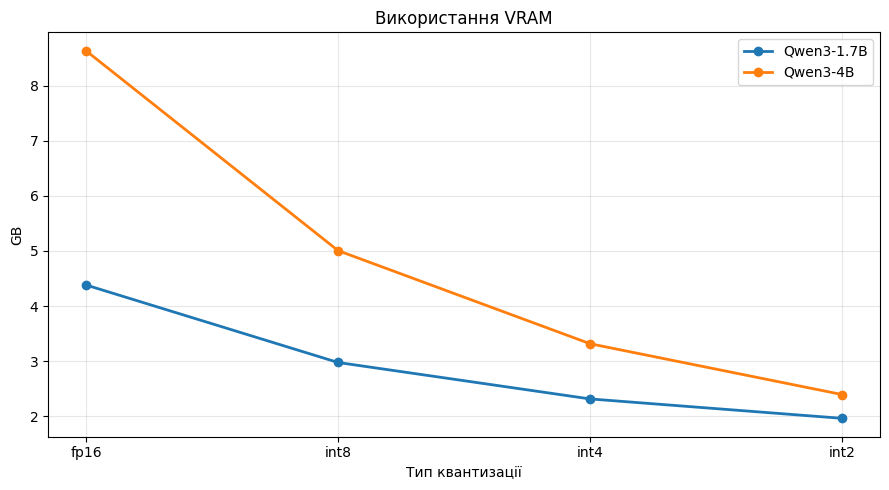

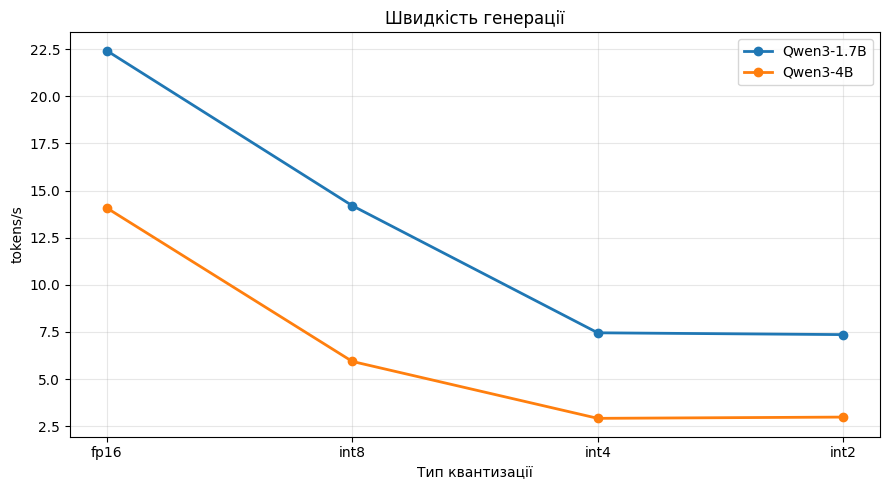

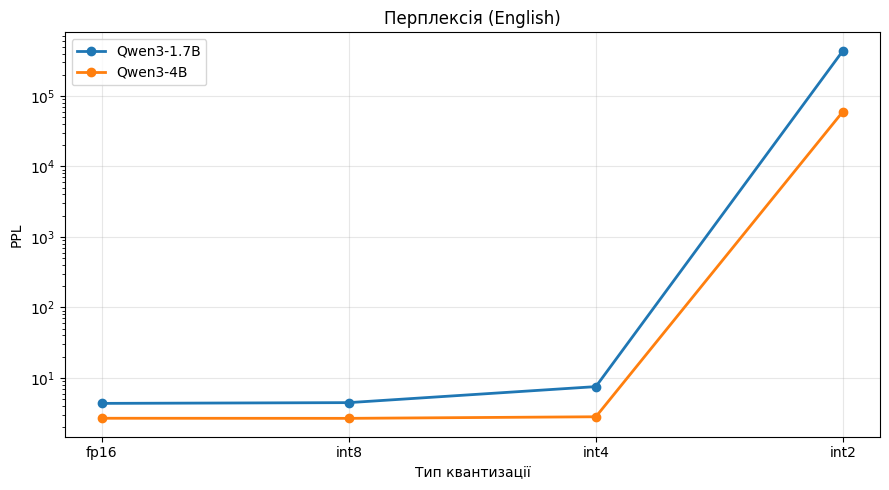

In [50]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("comparison_results.csv")

metrics = [
    ("Пік VRAM (GB)", "Використання VRAM", "GB"),
    ("Швидкість (tokens/s)", "Швидкість генерації", "tokens/s"),
    ("перплексія, English", "Перплексія (English)", "PPL")
]

variants = ["fp16", "int8", "int4", "int2"]

for column, title, ylabel in metrics:
    plt.figure(figsize=(9, 5))

    for model_name, group in df.groupby("Модель"):
        group = group.set_index("Квантизація").loc[variants]
        plt.plot(
            variants,
            group[column],
            marker="o",
            linewidth=2,
            label=model_name
        )

    plt.title(title)
    plt.xlabel("Тип квантизації")
    plt.ylabel(ylabel)

    if "Перплексія" in title:
        plt.yscale("log")

    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.tight_layout()

    filename = {
        "Пік VRAM (GB)": "vram.png",
        "Швидкість (tokens/s)": "speed.png",
        "перплексія, English": "perplexity.png"
    }[column]

    plt.savefig(filename, dpi=300)
    plt.show()

In [51]:
%pip -q install sacrebleu

In [52]:
from sacrebleu.metrics import CHRF
import pandas as pd

chrf = CHRF()

references = [ref for src, ref in TRANSLATION]

rows = []

for model_name, results in [
    ("Qwen3-4B", records_4b),
    ("Qwen3-1.7B", records_17b)
]:
    for variant, r in results.items():
        predictions = r["переклади"]

        score = chrf.corpus_score(
            predictions,
            [references]
        ).score

        rows.append({
            "Модель": model_name,
            "Квантизація": variant,
            "chrF": round(score, 2)
        })

chrf_df = pd.DataFrame(rows)

display(chrf_df)

,Модель,Квантизація,chrF
0,Qwen3-4B,fp16,55.22
1,Qwen3-4B,int8,58.25
2,Qwen3-4B,int4,55.34
3,Qwen3-4B,int2,0.19
4,Qwen3-1.7B,fp16,8.64
5,Qwen3-1.7B,int8,9.13
6,Qwen3-1.7B,int4,10.10
7,Qwen3-1.7B,int2,0.11


Менша модель Qwen3-1.7B демонструє значно нижчу якість перекладу, ніж Qwen3-4B (chrF 8.64 проти 55.22 для fp16). Квантизація int8 та int4 відносно мало впливає на якість, тоді як int2 призводить до критичного погіршення перплексії та chrF в обох моделях.

### Додатковий вимір для питання 13

Одна окрема перевірка перплексії на осмисленому та випадковому українському тексті для Qwen3-4B-Instruct-2507 у fp16. Запускайте лише наступну комірку: повторне виконання повного циклу квантизацій не потрібне.


In [55]:

import gc
import torch
from transformers import AutoTokenizer, AutoModelForCausalLM

_ppl13_model_id = "Qwen/Qwen3-4B-Instruct-2507"
_ppl13_tokenizer = AutoTokenizer.from_pretrained(_ppl13_model_id)
_ppl13_model = AutoModelForCausalLM.from_pretrained(
    _ppl13_model_id,
    torch_dtype=torch.float16,
    device_map="auto"
)
_ppl13_model.eval()

_ppl13_meaningful = PPL_TEXT["Українська"]
_ppl13_random = "стілець космос чайник річка автомобіль"

def _ppl13_measure(txt):
    ids = _ppl13_tokenizer(txt, return_tensors="pt").input_ids
    ids = ids.to(next(_ppl13_model.parameters()).device)
    with torch.inference_mode():
        loss = _ppl13_model(ids, labels=ids).loss
    return torch.exp(loss).item()

_ppl13_reference = _ppl13_measure(_ppl13_meaningful)
_ppl13_random_result = _ppl13_measure(_ppl13_random)
print(f"Осмислений український текст — PPL: {_ppl13_reference:.3f}")
print(f"Випадкові слова — PPL: {_ppl13_random_result:.3f}")
print("Порівняння:", "вище" if _ppl13_random_result > _ppl13_reference else "не вище", "для випадкових слів")

del _ppl13_model
gc.collect()
if torch.cuda.is_available():
    torch.cuda.empty_cache()


Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

Осмислений український текст — PPL: 2.400
Випадкові слова — PPL: 46.910
Порівняння: вище для випадкових слів


# 0.1. Відповіді на теоретичні питання

### Питання 1. Помилка підрахунку літер

Модель працює з токенами, а не безпосередньо з окремими літерами, тому може помилятися під час підрахунку символів навіть у режимі міркування. У слові «трансформер» літера «р» зустрічається тричі, що підтверджує код:

```python
word = "трансформер"
print(word.count("р"))  
```

### Питання 2. Вплив квантизації на якість

Від fp16 до int4 перплексія зростає незначно, а якість перекладу залишається відносно стабільною. При переході від int4 до int2 відбувається найбільший стрибок: англійська перплексія зростає з 2.81 до 60091.86, а chrF падає з 55.34 до 0.19.

### Питання 3. Перплексія для різних мов

Перплексія зростає неоднаково: при int2 для англійської вона досягає 60091.86, а для української — 34451480. Це узгоджується з висновком лекції, що квантизація може сильніше погіршувати якість для менш представлених мов.

### Питання 4. Сліпе порівняння та автоматичні метрики

У сліпому порівнянні fp16 виявилася кращою двічі, int4 — один раз, а ще двічі відповіді були приблизно однаковими. Це загалом узгоджується з автоматичними метриками, які показали невелику різницю між fp16 та int4, хоча суб'єктивна якість окремих відповідей відрізнялася.

### Питання 5. Відмінності BLEU та chrF

Наприклад, еталонний переклад «Зустріч перенесли на четвер на третю годину» модель передала як «Зустріч була перенесена на четвер, о 15 годин». Попри близький зміст, BLEU знижує оцінку через відмінності у словах і їхньому порядку, а chrF частково враховує схожість на рівні символів.

### Питання 6. Економія пам'яті та швидкість генерації

Пам'ять моделі зменшилася з 8.04 GB для fp16 до 4.42 GB (int8), 2.73 GB (int4) та 1.81 GB (int2), тобто приблизно в 1.82, 2.95 та 4.44 раза відповідно. Скорочення не є точно пропорційним кількості бітів через службові дані та неквантизовані компоненти, а генерація не прискорилася через накладні витрати квантизації.

### Питання 7. Поведінка Base-моделі

Base-модель навчена продовжувати текст, а не виконувати інструкції, тому може генерувати нові питання замість відповіді. Промпт із прикладами, фактично виконаний у розділі 1.2:

```python
prompt = """
What is the capital of Germany?
answer - Berlin

What is the capital of Italy?
answer - Rome

What is the capital of Spain?
answer - Madrid

What is the capital of France?
"""
print(generate_raw(BASE_MODEL, prompt, max_tokens=15))
```

Результат виконання:

```text
answer - Paris

What is the capital of Japan?
answer - Tokyo
```

Модель правильно відповіла «Paris», після чого продовжила генерувати текст у заданому форматі.

### Питання 8. Витрати на міркування

Без міркувань модель використала 252 токени за 2.1 секунди, а з міркуваннями — 569 токенів за 4.9 секунди; обидва режими дали відповідь 9. Модель може міркувати англійською через значну частку англомовних навчальних даних і сформовані під час навчання шаблони міркування.

### Питання 9. Переваги режиму міркування

Для перевірки використано задачу, у якій одна людина завжди говорить правду, одна завжди бреше, а третя може говорити як правду, так і неправду:

```text
Є три людини: Анна, Богдан і Віктор.
Один завжди говорить правду, один завжди бреше,
а третій може говорити як правду, так і неправду.
Анна каже: «Богдан завжди бреше».
Богдан каже: «Віктор завжди говорить правду».
Віктор каже: «Я не той, хто завжди говорить правду».
Визнач, хто з них завжди говорить правду,
хто завжди бреше, а хто може говорити будь-що.
```

**Без міркувань:** Анна — правдоруб, Богдан — брехун, Віктор — правдоруб.

**З міркуваннями:** Анна завжди говорить правду, Богдан завжди бреше, Віктор може говорити правду або неправду.

Режим міркування визначив ролі відповідно до умов задачі, тоді як без нього модель помилково віднесла Віктора до правдорубів.

### Питання 10. Параметри генерації

`temperature: 0` робить генерацію максимально передбачуваною, а `seed: 1` фіксує початкове значення генератора випадкових чисел. Це зменшує випадкові відмінності між запусками та допомагає порівнювати результати експериментів.

### Питання 11. Вибір fp16 замість bf16

Відеокарта NVIDIA T4 має compute capability 7.5, що можна перевірити функцією `torch.cuda.get_device_capability()`. Архітектура Turing не підтримує bf16 апаратно так, як новіші покоління GPU, тому для експерименту використовується fp16.

### Питання 12. Кількість параметрів і пам'ять моделі

Модель Qwen3-4B має приблизно 4 млрд параметрів, тому за формулою `4 млрд × 2 байти` її fp16-версія має займати близько 8 GB пам'яті. У результатах експерименту пам'ять моделі становила 8.04 GB, що практично збігається з теоретичною оцінкою.

### 13. Перплексія та осмисленість тексту

Перплексія показує, наскільки добре модель передбачає наступні токени: чим нижче значення, тим краще. Її некоректно безпосередньо порівнювати між англійською та українською через відмінності токенізації. Експеримент показав, що для осмисленого українського тексту PPL = 2.330, а для випадкового набору слів — 46.910, оскільки непов'язану послідовність слів моделі значно складніше передбачити.

### Питання 14. Пікове використання VRAM

Пік VRAM більший за пам'ять моделі, оскільки під час генерації додатково зберігаються KV-кеш, активації, проміжні результати обчислень і службові буфери. Наприклад, для fp16 пам'ять моделі становила 8.04 GB, а пікове використання VRAM — 8.64 GB.

### Питання 15. Надійність сліпого порівняння

У п'яти порівняннях fp16 було обрано 2 рази, int4 — 1 раз, а варіант «однаково» — 2 рази. П'яти прикладів недостатньо для надійних висновків; бажано провести хоча б кілька десятків порівнянь, а для статистично обґрунтованого висновку визначити необхідну вибірку за очікуваною різницею та точністю оцінки.

### Питання 16. Деградація моделі в int2

У збережених генераціях int2 модель часто втрачає зв'язність тексту: з'являються повторення, беззмістовні фрагменти та випадкові символи, а інструкція перестає виконуватися коректно. В int4 таких критичних збоїв у перевірених відповідях не спостерігалося, хоча траплялися неточності й менш вдалі формулювання.

### Питання 17. Квантизація меншої моделі

За перплексією квантизація до int4 сильніше погіршила результат Qwen3-1.7B (4.35 → 7.52), ніж Qwen3-4B (2.67 → 2.81). Водночас chrF для 1.7B при fp16/int8/int4 становив 8.64/9.13/10.10, а для 4B — 55.22/58.25/55.34; при int2 обидві моделі різко деградували (chrF 0.11 та 0.19 відповідно). Порівняння не ізолює вплив розміру: тестувалися Qwen3-4B-Instruct-2507 та Qwen3-1.7B, які також відрізняються версією і налаштуванням навчання.

### Питання 18. Параметр OLLAMA_NUM_PARALLEL

Параметр `OLLAMA_NUM_PARALLEL` визначає максимальну кількість запитів, які Ollama може одночасно обробляти для однієї моделі. Збільшення цього значення дозволяє обслуговувати більше користувачів паралельно, але підвищує використання оперативної або відеопам'яті.

### Питання 19. Формат bf16 у сучасних моделях

Формат bf16 має такий самий діапазон порядку величин, як fp32, але використовує лише 16 біт замість 32. Це дозволяє скоротити використання пам'яті, зберігаючи кращу числову стійкість до переповнення порівняно з fp16.

### Питання 20. Протокол OpenAI

OpenAI-сумісний API дозволяє різним моделям і рантаймам використовувати однаковий формат запитів, що спрощує інтеграцію та заміну моделей у застосунках. Завдяки цьому програми, які працюють із моделями OpenAI, можна адаптувати для локальних моделей без значних змін у коді.

# 1. Локальна модель і власний застосунок



## 1.1. Характеристики комп'ютера

| Компонент | Характеристики | Джерело |
|---|---|---|
| Процесор | AMD Ryzen 5 220, 6 ядер / 12 потоків | AMD |
| RAM | 16 GB | Диспетчер завдань |
| Інтегрована графіка | AMD Radeon 740M | AMD |
| Відеокарта | NVIDIA RTX 5050 Laptop | NVIDIA |
| VRAM | 8 GB GDDR7 | NVIDIA |
| Пропускна здатність VRAM | 384 GB/s | Специфікація відеопам'яті |

Для запуску моделей використовується дискретна відеокарта.

## 1.2. Розрахунок

Для запуску обрано Qwen3-4B-Instruct-2507. Відеокарта RTX 5050 Laptop має 8 GB VRAM.

За формулою:

Пам'ять = P * Q / 8 * (1 + O), де O = 0.2 (запас 20%).

- fp16: 4 * 16 / 8 * 1.2 = 9.6 GB
- int8: 4 * 8 / 8 * 1.2 = 4.8 GB
- int4: 4 * 4 / 8 * 1.2 = 2.4 GB

Для GGUF розміри ваг становлять приблизно 2.50 GB (Q4_K_M) та 3.31 GB (Q6_K).

KV-кеш для контексту 4096 токенів:

KV = 2 * 36 * 8 * 128 * 2 * 4096 = 0.604 GB.

З урахуванням запасу 20%:

- Q4_K_M: 2.50 * 1.2 + 0.604 = 3.60 GB
- Q6_K: 3.31 * 1.2 + 0.604 = 4.58 GB

Теоретична швидкість генерації:

Швидкість = пропускна здатність VRAM / (ваги + KV-кеш)

- Q4_K_M: 384 / (2.50 + 0.604) = 123.7 tokens/s
- Q6_K: 384 / (3.31 + 0.604) = 98.1 tokens/s

Отже, обидві квантизації поміщаються у 8 GB VRAM. Для початкового тестування обрано Q4_K_M, а для порівняння після оптимізації — Q6_K. Реальна швидкість буде нижчою за розрахункову.

## 1.3. Вибір моделі й рантайму

Обрано Qwen3-4B-Instruct-2507 у форматі GGUF з квантизацією Q4_K_M, оскільки вона поміщається у 8 GB VRAM та забезпечує компроміс між швидкістю і якістю.

Для запуску використовую Ollama, оскільки вона підтримує NVIDIA GPU та OpenAI-сумісний API. Обрано Instruct-модель без режиму міркування, щоб зменшити час генерації відповіді.

## 1.4. Вимірювання продуктивності

Тестування проведено за допомогою bench.py з міткою before.

| Клієнтів | Помилок | TTFT p50, с | TTFT p95, с | tokens/s | Throughput |
|---|---|---|---|---|---|
| 1 | 0 | 2.10 | 2.12 | 82.5 | 35.8 |
| 2 | 0 | 2.41 | 4.28 | 84.0 | 61.8 |
| 4 | 0 | 5.12 | 7.17 | 84.6 | 77.2 |
| 8 | 0 | 10.37 | 13.11 | 84.6 | 78.4 |

Модель повністю працює на GPU, займає 3.2 GB пам'яті,
контекст — 4096 токенів.

Розрахункова швидкість становила 123.7 tokens/s,
фактична — 82.5 tokens/s (66.7% від теоретичної).
При збільшенні кількості клієнтів зростає час
очікування першого токена, але підвищується
загальна пропускна здатність.

## 1.5. Оптимізація

Для покращення якості відповідей було перевірено квантизацію Q6_K.

| Показник | Q4_K_M | Q6_K |
|---|---:|---:|
| Швидкість, tokens/s | 82.5 | 71.8 |
| TTFT p50, с (1 клієнт) | 2.10 | 2.06 |
| Throughput (8 клієнтів) | 78.4 | 66.1 |
| Кількість помилок | 0 | 8 |

Швидкість генерації зменшилася приблизно на 13%.
Суттєвого покращення якості відповідей не виявлено.
Тому для застосунку залишаю Q4_K_M, оскільки вона
швидша та стабільніша.

## 1.6. Власний застосунок

Розроблено вебзастосунок QuizLab для генерації навчальних
тестів за допомогою локальної моделі Qwen3-4B-Instruct Q4_K_M.

Застосунок написано на HTML, CSS та JavaScript.
Взаємодія з моделлю відбувається через OpenAI-сумісний API Ollama.

Функціонал:
- Вибір теми, мови, складності та кількості питань.
- Генерація та проходження тестів.
- Перевірка відповідей і підрахунок результату.
- Індикатор очікування та обробка помилок.

Параметри генерації:
- Temperature — 0.2 для зменшення випадковості.
- Max tokens — 2048 для обмеження довжини відповіді.
- Context — 4096 токенів для економії відеопам'яті.

Відповідь моделі повертається у форматі JSON.
Інструкція запуску знаходиться у README.md.

## 1.7. Перевірка та демонстрація

| Сценарій | Очікуваний результат | Фактичний результат |
|---|---|---|
| Генерація 3 питань з ООП | Коректний тест | виконано |
| Генерація 8 питань з історії | 8 питань |виконано |
| Тест англійською мовою | Питання англійською | виконано |
| Порожня тема | Заборона генерації | виконано |
| Перевірка без відповідей | Повідомлення про помилку | виконано |
| Вимкнена Ollama | Помилка з'єднання | виконано |
| Права людини та цензура в Китаї | Коректний тест | виконано но з нюансами |
| Події на площі Тяньаньмень 1989 року | Історично коректний тест | Не виконано |

### Помилки моделі

Під час генерації тесту про події на площі Тяньаньмень
модель пропускала важливі історичні факти та створювала
неоднозначні питання. Уточнення теми не усунуло проблему.

Також модель повертала некоректну структуру JSON,
але застосунок обробив помилку без аварійного завершення.

## 1.8. Мій звіт

- **Залізо:** Ryzen 5 220, 16 GB RAM, RTX 5050 Laptop, 8 GB VRAM.
- **Розрахунок:** теоретична швидкість Q4_K_M — 123.7 tokens/s.
- **Модель і рантайм:** Qwen3-4B-Instruct-2507, Q4_K_M, Ollama.
- **До оптимізації:** 82.5 tokens/s, без помилок.
- **Після оптимізації:** Q6_K показала 71.8 tokens/s та 8 помилок, тому залишено Q4_K_M.
- **Застосунок:** QuizLab — генератор навчальних тестів. Temperature — 0.2, max tokens — 2048, context — 4096.
- **Тестування:** перевірено генерацію тестів, обробку помилок та крайові випадки. Виявлено неточності на історичних темах.

**Висновок:** Q4_K_M забезпечує кращий баланс швидкості, якості та стабільності на моєму обладнанні. Розроблений застосунок дозволяє використовувати локальну модель без хмарних сервісів.